# Dimensão complementar — Uso de Inteligência Artificial

## Pergunta de investigação

Como os participantes incorporam ferramentas de inteligência artificial generativa em suas atividades profissionais relacionadas ao trabalho com dados?

## Objetivo

Investigar a frequência de utilização e as finalidades de uso de ferramentas de inteligência artificial generativa pelos participantes, identificando como essas tecnologias estão sendo incorporadas às práticas profissionais.

## Variáveis analisadas

- **Frequência de utilização:** recorrência declarada de uso de ferramentas de IA generativa no trabalho com dados.
- **Finalidades de utilização:** atividades profissionais para as quais os participantes declaram utilizar essas ferramentas.
- **Diversidade de aplicações:** variedade de finalidades assinaladas pelos participantes.

## Estratégia de análise

A investigação está organizada em duas dimensões:

1. **Frequência de utilização:** análise da distribuição das respostas entre os diferentes níveis de frequência, observando a presença da inteligência artificial nas atividades profissionais.
2. **Finalidades de utilização:** identificação das aplicações mais recorrentes, considerando as atividades assinaladas pelos participantes e a diversidade de usos declarados.

A análise contempla a distribuição das finalidades de uso declaradas pelos participantes. Os cruzamentos exploratórios previstos no plano de análise foram considerados, mas não executados, em razão dos limites do universo de respostas e das condições para produzir comparações interpretáveis.

## Cuidados metodológicos

As perguntas sobre inteligência artificial foram incorporadas ao formulário durante o período de coleta. Por esse motivo, esta análise considera exclusivamente as **18 respostas válidas** registradas nessa dimensão, e não os 54 participantes contemplados nos quatro eixos principais da pesquisa.

As 36 respostas ausentes na base principal decorrem da inclusão posterior dessas perguntas. Portanto, não devem ser interpretadas como ausência de utilização de ferramentas de inteligência artificial.

A pergunta sobre finalidades permite múltiplas seleções. Assim, as frequências representam o número de participantes que assinalaram cada alternativa, e a soma dos percentuais poderá ultrapassar 100%.

Os resultados expressam as práticas declaradas pelos participantes que responderam às questões e devem ser interpretados como evidências exploratórias da amostra, sem generalização para o conjunto dos profissionais de tecnologia.

A frequência e as finalidades de utilização, isoladamente, não permitem avaliar domínio técnico, maturidade no uso, qualidade das entregas, ganhos de produtividade ou impactos decorrentes da adoção dessas ferramentas.

Esta dimensão possui caráter complementar e amplia a leitura dos quatro eixos principais da pesquisa — Perfil profissional, Jornada, Realidade e Olhando para frente — sem constituir um quinto eixo analítico.

 # 01 — Preparação e verificação da base

*Importações, carregamento da fonte original, verificação de integridade e seleção das variáveis.*

In [13]:
# Preparação da base

# Bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Configurações de exibição
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Diretório de execução
diretorio_atual = Path.cwd()

print("Ambiente de análise preparado.")

Ambiente de análise preparado.


In [14]:
# ============================================================
# 01 — LOCALIZAÇÃO E INSPEÇÃO DOS ARQUIVOS DE DADOS
# ============================================================

from pathlib import Path

# 1. Identificação automática da raiz do projeto
# Procura, no diretório atual e nos diretórios superiores,
# aquele que contém as pastas "data" e "notebooks".

diretorios_candidatos = [Path.cwd(), *Path.cwd().parents]

raiz_projeto = next(
    (
        diretorio
        for diretorio in diretorios_candidatos
        if (diretorio / "data").is_dir() and (diretorio / "notebooks").is_dir()
    ),
    None,
)

if raiz_projeto is None:
    raise FileNotFoundError(
        "Não foi possível identificar a raiz do projeto. "
        "Verifique se as pastas 'data' e 'notebooks' "
        "estão presentes na estrutura do projeto."
    )


# 2. Definição da pasta e das extensões a inspecionar

pasta_dados = raiz_projeto / "data"

extensoes_dados = {".csv", ".xlsx", ".xls"}

pastas_ignoradas = {".venv", "venv", "__pycache__", ".ipynb_checkpoints"}


# 3. Localização dos arquivos de dados

arquivos_encontrados = [
    arquivo
    for arquivo in pasta_dados.rglob("*")
    if arquivo.is_file()
    and arquivo.suffix.lower() in extensoes_dados
    and not any(pasta in pastas_ignoradas for pasta in arquivo.parts)
]


# 4. Organização dos resultados da inspeção

arquivos_encontrados = sorted(
    arquivos_encontrados,
    key=lambda arquivo: str(arquivo.relative_to(raiz_projeto)).lower(),
)


# 5. Apresentação do resultado

print("INSPEÇÃO DOS ARQUIVOS DE DADOS")
print("=" * 60)

print(f"Arquivos localizados: {len(arquivos_encontrados)}")
print()

for arquivo in arquivos_encontrados:
    caminho_relativo = arquivo.relative_to(raiz_projeto)
    print(f"- {caminho_relativo}")

print()
print("Inspeção concluída.")

INSPEÇÃO DOS ARQUIVOS DE DADOS
Arquivos localizados: 3

- data\derivados\base_analitica_inicial.csv
- data\derivados\base_analitica_v1.csv
- data\fonte_original\Pesquisa — Um Olhar de Quem Está no Campo - BASELINE_36_RESPOSTAS.csv

Inspeção concluída.


In [15]:
# 01 — Carregamento da base original e seleção das variáveis de IA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Caminho da fonte original
caminho_fonte = (
    raiz_projeto
    / "data"
    / "fonte_original"
    / "Pesquisa — Um Olhar de Quem Está no Campo - BASELINE_36_RESPOSTAS.csv"
)

# Carregamento
df_original = pd.read_csv(caminho_fonte)

# Identificação das colunas
colunas_disponiveis = {coluna.strip(): coluna for coluna in df_original.columns}

coluna_frequencia_ia = next(
    coluna
    for nome, coluna in colunas_disponiveis.items()
    if nome.startswith("Com que frequência você utiliza ferramentas de IA")
)

coluna_finalidades_ia = next(
    coluna
    for nome, coluna in colunas_disponiveis.items()
    if nome.startswith("Para quais dessas finalidades")
)

# Seleção das variáveis
df_ia = df_original[[coluna_frequencia_ia, coluna_finalidades_ia]].copy()

# Verificação do universo de respostas
print("BASE ORIGINAL")
print(f"Dimensões: {df_original.shape}")

print("\nDIMENSÃO COMPLEMENTAR — IA")
print(f"Respostas válidas — frequência: {df_ia[coluna_frequencia_ia].notna().sum()}")
print(f"Respostas válidas — finalidades: {df_ia[coluna_finalidades_ia].notna().sum()}")

BASE ORIGINAL
Dimensões: (54, 17)

DIMENSÃO COMPLEMENTAR — IA
Respostas válidas — frequência: 18
Respostas válidas — finalidades: 18


In [16]:
# 02 — Frequência de utilização de ferramentas de IA

# Seleção das 18 respostas válidas
frequencia_ia = df_ia[coluna_frequencia_ia].dropna()

total_respostas = len(frequencia_ia)

# Apuração das frequências
tabela_frequencia_ia = (
    frequencia_ia.value_counts(sort=False)
    .rename_axis("Frequência declarada")
    .reset_index(name="Participantes")
)

# Cálculo dos percentuais sobre as respostas válidas
tabela_frequencia_ia["Percentual"] = (
    tabela_frequencia_ia["Participantes"] / total_respostas * 100
).round(1)

# Apresentação dos resultados
print("FREQUÊNCIA DE UTILIZAÇÃO DE IA")
print("=" * 65)
print(f"Total de respostas válidas: {total_respostas}\n")

display(tabela_frequencia_ia)

print("\nConferência:")
print(f"Total de participantes: {tabela_frequencia_ia['Participantes'].sum()}")
print(f"Total percentual: {tabela_frequencia_ia['Percentual'].sum():.1f}%")

FREQUÊNCIA DE UTILIZAÇÃO DE IA
Total de respostas válidas: 18



,Frequência declarada,Participantes,Percentual
0,Diariamente ou quase todos os dias,8,44.4
1,Está integrado ao meu fluxo de trabalho (uso c...,9,50.0
2,Algumas vezes por semana,1,5.6



Conferência:
Total de participantes: 18
Total percentual: 100.0%


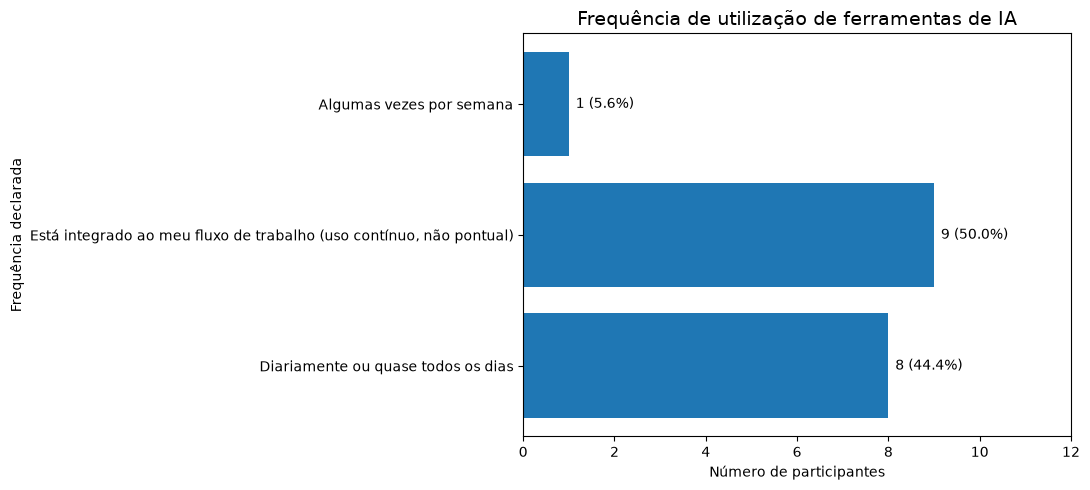

In [17]:
# ============================================================
# 02 — VISUALIZAÇÃO DA FREQUÊNCIA DE UTILIZAÇÃO DE IA
# ============================================================

import matplotlib.pyplot as plt

# 1. Configuração da figura

plt.figure(figsize=(11, 5))

# 2. Construção do gráfico

barras = plt.barh(
    tabela_frequencia_ia["Frequência declarada"], tabela_frequencia_ia["Participantes"]
)

# 3. Inclusão dos valores e percentuais nas barras

for barra, percentual in zip(barras, tabela_frequencia_ia["Percentual"]):
    largura = barra.get_width()

    plt.text(
        largura + 0.15,
        barra.get_y() + barra.get_height() / 2,
        f"{int(largura)} ({percentual:.1f}%)",
        va="center",
    )

# 4. Configuração dos elementos visuais

plt.title("Frequência de utilização de ferramentas de IA", fontsize=14)

plt.xlabel("Número de participantes")
plt.ylabel("Frequência declarada")

plt.xlim(0, tabela_frequencia_ia["Participantes"].max() + 3)

plt.tight_layout()

# 5. Exibição do gráfico

plt.show()

### Leitura analítica — Frequência de utilização

Entre os 18 participantes que responderam ao bloco complementar, observa-se uma presença recorrente das ferramentas de inteligência artificial generativa no trabalho com dados.

Nove participantes (50%) afirmaram que o uso está integrado ao fluxo de trabalho, enquanto oito (44,4%) declararam utilizar essas ferramentas diariamente ou quase todos os dias. Apenas um participante (5,6%) indicou utilização algumas vezes por semana.

Em conjunto, 17 dos 18 respondentes (94,4%) declararam uso diário ou contínuo dessas ferramentas.

Os resultados evidenciam a presença da IA nas práticas profissionais desse grupo. Entretanto, a frequência de utilização, isoladamente, não permite avaliar o grau de domínio das ferramentas, a qualidade de seu uso ou os impactos sobre a produtividade.

In [18]:
# ============================================================
# 03 — APURAÇÃO DAS FINALIDADES DE UTILIZAÇÃO DE IA
# ============================================================

import re
import pandas as pd

# 1. Alternativas originais do questionário

finalidades_ia = [
    "Geração ou revisão de código/scripts",
    "Análise e interpretação de dados ou informações",
    "Redação e revisão de textos (relatórios, documentação, e-mails, propostas)",
    "Automação de tarefas ou processos repetitivos",
    "Pesquisa e síntese de informações",
    "Planejamento, priorização ou apoio à tomada de decisão",
    "Criação ou revisão de conteúdo visual/design",
    "Construção de soluções com IA (integrações, agentes, pipelines)",
    "Nunca utilizei",
]


# 2. Seleção das respostas válidas

respostas_finalidades = df_ia[coluna_finalidades_ia].dropna().astype(str)

total_participantes = len(respostas_finalidades)

if total_participantes == 0:
    raise ValueError(
        "Não foram encontradas respostas válidas "
        "para as finalidades de utilização de IA."
    )


# 3. Contagem de participantes por finalidade

resultados_finalidades = []

for finalidade in finalidades_ia:

    quantidade = respostas_finalidades.apply(
        lambda resposta: bool(
            re.search(re.escape(finalidade), resposta, flags=re.IGNORECASE)
        )
    ).sum()

    percentual = round(quantidade / total_participantes * 100, 1)

    resultados_finalidades.append(
        {
            "Finalidade": finalidade,
            "Participantes": int(quantidade),
            "Percentual": percentual,
        }
    )


# 4. Organização da tabela de resultados

tabela_finalidades_ia = pd.DataFrame(resultados_finalidades)

tabela_finalidades_ia = tabela_finalidades_ia.sort_values(
    by="Participantes", ascending=False
).reset_index(drop=True)


# 5. Apresentação dos resultados

print("FINALIDADES DE UTILIZAÇÃO DE IA")
print("=" * 65)

print(f"Participantes considerados: {total_participantes}\n")

display(tabela_finalidades_ia)


# 6. Conferência dos resultados

total_marcacoes = tabela_finalidades_ia["Participantes"].sum()

soma_percentuais = tabela_finalidades_ia["Percentual"].sum()

print("\nCONFERÊNCIA DOS RESULTADOS")
print("=" * 65)

print(f"Total de marcações: {total_marcacoes}")

print(f"Soma dos percentuais: {soma_percentuais:.1f}%")

print(
    "\nObservação: a questão permite múltiplas seleções. "
    "Por isso, um participante pode aparecer em mais de "
    "uma finalidade e a soma dos percentuais pode "
    "ultrapassar 100%."
)

FINALIDADES DE UTILIZAÇÃO DE IA
Participantes considerados: 18



,Finalidade,Participantes,Percentual
0,Geração ou revisão de código/scripts,17,94.4
1,"Redação e revisão de textos (relatórios, docum...",15,83.3
2,Análise e interpretação de dados ou informações,13,72.2
3,Automação de tarefas ou processos repetitivos,11,61.1
4,Pesquisa e síntese de informações,11,61.1
5,"Planejamento, priorização ou apoio à tomada de...",9,50.0
6,"Construção de soluções com IA (integrações, ag...",7,38.9
7,Criação ou revisão de conteúdo visual/design,5,27.8
8,Nunca utilizei,0,0.0



CONFERÊNCIA DOS RESULTADOS
Total de marcações: 88
Soma dos percentuais: 488.8%

Observação: a questão permite múltiplas seleções. Por isso, um participante pode aparecer em mais de uma finalidade e a soma dos percentuais pode ultrapassar 100%.


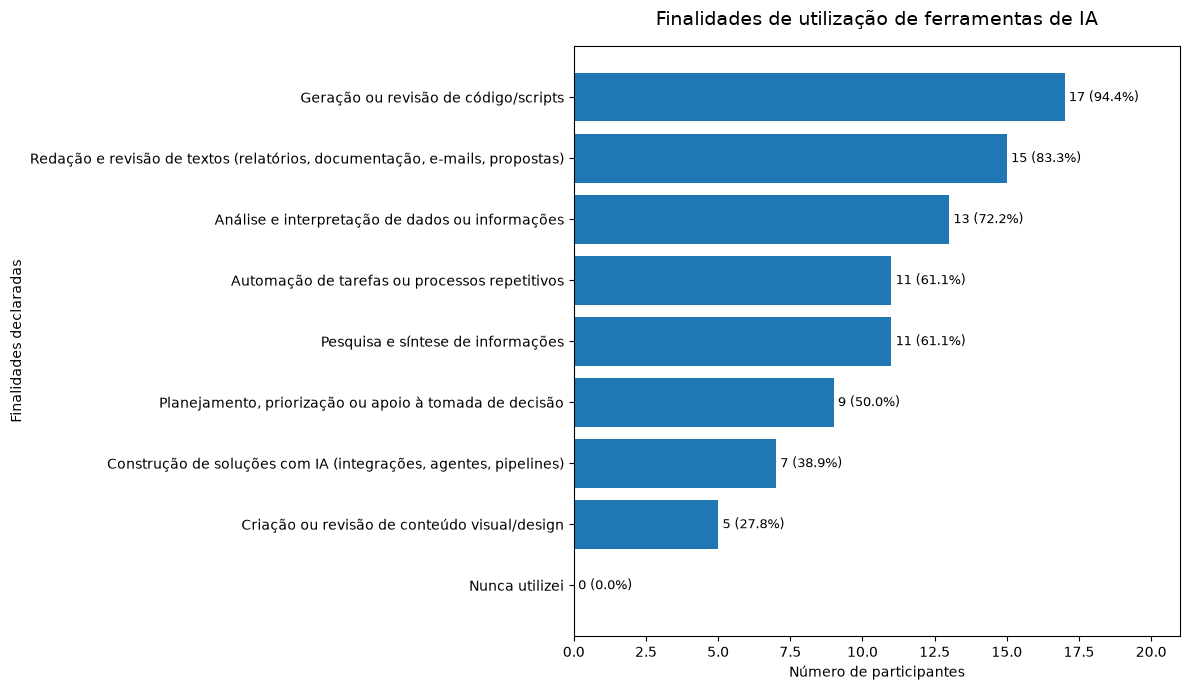

In [19]:
# ============================================================
# 03 — VISUALIZAÇÃO DAS FINALIDADES DE UTILIZAÇÃO DE IA
# ============================================================

import matplotlib.pyplot as plt

# 1. Configuração da figura

plt.figure(figsize=(12, 7))

# 2. Construção do gráfico de barras horizontais

barras = plt.barh(
    tabela_finalidades_ia["Finalidade"], tabela_finalidades_ia["Participantes"]
)

# 3. Inclusão das quantidades e dos percentuais

for barra, percentual in zip(barras, tabela_finalidades_ia["Percentual"]):
    largura = barra.get_width()

    plt.text(
        largura + 0.15,
        barra.get_y() + barra.get_height() / 2,
        f"{int(largura)} ({percentual:.1f}%)",
        va="center",
        fontsize=9,
    )

# 4. Configuração dos elementos visuais

plt.title("Finalidades de utilização de ferramentas de IA", fontsize=14, pad=15)

plt.xlabel("Número de participantes")
plt.ylabel("Finalidades declaradas")

plt.xlim(0, tabela_finalidades_ia["Participantes"].max() + 4)

plt.gca().invert_yaxis()

plt.tight_layout()

# 5. Exibição do gráfico

plt.show()

### Leitura analítica — Finalidades de utilização

Entre os 18 participantes que responderam ao bloco complementar, a finalidade mais mencionada foi a geração ou revisão de código e scripts, assinalada por 17 participantes (94,4%). Em seguida, aparece a redação e revisão de textos, com 15 indicações (83,3%), seguida pela análise e interpretação de dados ou informações, mencionada por 13 participantes (72,2%).

Também se destacam a automação de tarefas ou processos repetitivos e a pesquisa e síntese de informações, ambas com 11 indicações (61,1%). O planejamento, a priorização e o apoio à tomada de decisão foram mencionados por nove participantes (50%).

As finalidades menos frequentes foram a construção de soluções com IA, com sete indicações (38,9%), e a criação ou revisão de conteúdo visual e design, com cinco (27,8%).

A distribuição revela uma concentração do uso em atividades de desenvolvimento, produção e análise de informações. Ao mesmo tempo, demonstra que a incorporação da IA não se restringe à programação, alcançando diferentes atividades da rotina profissional.

Esses resultados descrevem as finalidades declaradas pelos participantes. Não permitem, isoladamente, afirmar ganhos de produtividade, qualidade das entregas ou nível de domínio das ferramentas.

## 04 — Cruzamentos exploratórios

O plano de análise previa dois cruzamentos exploratórios, cuja execução dependeria da disponibilidade dos dados e da possibilidade de produzir comparações interpretáveis.

**Frequência × finalidades de utilização:** o cruzamento não foi executado. A distribuição da frequência concentra 17 dos 18 participantes em duas categorias, enquanto apenas um participante declarou utilização algumas vezes por semana. Essa concentração limita a comparação entre grupos.

**Frequência × características profissionais:** o cruzamento também não foi executado. Sua realização exigiria relacionar as 18 respostas do bloco complementar à base principal e verificar a distribuição dos participantes por área de atuação, tempo de experiência ou faixa etária. Essa investigação não foi desenvolvida nesta etapa.

Dessa forma, a dimensão permanece descritiva, concentrada na frequência e nas finalidades declaradas pelos 18 participantes.

## 05 — Síntese analítica — Uso de ferramentas de inteligência artificial

A análise do bloco complementar revela que, entre os 18 participantes que responderam às questões sobre inteligência artificial, as ferramentas de IA generativa já estão presentes de forma recorrente nas práticas profissionais relacionadas ao trabalho com dados.

Em relação à frequência, nove participantes (50%) afirmaram que o uso está integrado ao fluxo de trabalho, enquanto oito (44,4%) declararam utilizar essas ferramentas diariamente ou quase todos os dias. Apenas um participante (5,6%) indicou utilização algumas vezes por semana. Assim, 94,4% dos respondentes declararam uso diário ou integrado à rotina profissional.

Quanto às finalidades, destaca-se a geração ou revisão de código e scripts, mencionada por 17 participantes (94,4%). A redação e revisão de textos aparece em seguida, com 15 indicações (83,3%), acompanhada pela análise e interpretação de dados ou informações, mencionada por 13 participantes (72,2%).

Também se destacam a automação de tarefas ou processos repetitivos e a pesquisa e síntese de informações, ambas com 11 indicações (61,1%). O planejamento, a priorização e o apoio à tomada de decisão foram mencionados por nove participantes (50%). Já a construção de soluções com IA recebeu sete indicações (38,9%), e a criação ou revisão de conteúdo visual e design, cinco (27,8%).

Em conjunto, os resultados mostram que a utilização da IA nesse grupo não se restringe à programação. As ferramentas aparecem associadas a diferentes atividades profissionais, abrangendo desenvolvimento, produção textual, análise de informações, automação, pesquisa, planejamento e criação.

### Limites de interpretação

Esta análise considera exclusivamente as 18 respostas válidas ao bloco complementar. As 36 respostas ausentes decorrem da inclusão posterior dessas perguntas no formulário e não podem ser interpretadas como ausência de utilização de IA.

Além disso, a questão sobre finalidades permitia múltiplas seleções. Portanto, os percentuais representam a proporção de participantes que assinalou cada alternativa, não sendo categorias exclusivas nem parcelas de um total de 100%.

Os resultados descrevem a frequência e as finalidades declaradas pelos participantes. Não permitem inferir, isoladamente, domínio técnico, maturidade no uso, ganhos de produtividade, qualidade das entregas ou impactos decorrentes da utilização dessas ferramentas.

### Articulação com os quatro eixos da pesquisa

A dimensão complementar amplia a compreensão das práticas profissionais investigadas nos quatro eixos principais — Perfil profissional, Jornada, Realidade e Olhando para frente — ao acrescentar evidências sobre a presença da inteligência artificial no cotidiano de trabalho dos participantes.

Seu papel é complementar a análise da pesquisa, oferecendo uma perspectiva específica sobre a incorporação dessas ferramentas, sem constituir um quinto eixo ou alterar a estrutura analítica principal.

## 06 — Encerramento da Dimensão Complementar — Uso de Inteligência Artificial

A análise complementar examinou a frequência e as finalidades de utilização de ferramentas de IA entre os 18 participantes que responderam ao bloco específico.

Os resultados ampliam a compreensão das práticas profissionais relacionadas ao trabalho com dados, considerando a presença da inteligência artificial no cotidiano dos participantes.

O recorte não permite generalizações para os 54 respondentes nem avaliações sobre domínio técnico, produtividade ou impacto do uso dessas ferramentas.

Com esta etapa, encerra-se a análise da dimensão complementar, preservando sua autonomia em relação aos quatro eixos principais da pesquisa.